# 04 - Sentinel-2 and Landsat

This notebook makes two tables:
- `sentinel2_monthly.csv`: NDVI per cell per month, 2016 to 2024 (the farm now)
- `landsat_yearly.csv`: NDVI per cell per year, 1985 to 2024 (40-year change)

Data source: Microsoft Planetary Computer (STAC). We read only our area. We never download full scenes.

In [ ]:
%pip install numpy pandas matplotlib pyproj earthengine-api


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Our area (from pilot_area.md) - do not change
W, S, E, N = 30.70, 31.05, 30.91, 31.30      # West, South, East, North
LAT_C, LON_C = 31.175, 30.805                # center point
START_YEAR, END_YEAR = 2016, 2024            # full years for the final tables

# Safety check: latitude starts with 31, longitude starts with 30
assert 31 <= S < N < 32, "Latitude is wrong. Did you swap lat and lon?"
assert 30 <= W < E < 31, "Longitude is wrong. Did you swap lat and lon?"
print("Area OK")

Area OK


## Why we did not use Microsoft Planetary Computer

Our first approach read Sentinel-2 through the Planetary Computer STAC catalog with `odc-stac`, downloading the pixels to this laptop. We abandoned it for two reasons.

**It was too slow.** One month of data took about 757 seconds, and some months reached 32 minutes. The full 108 months would have taken 22 to 57 hours. We did not have that time, and every network drop restarted a month from zero.

**The free compute was gone.** The Planetary Computer Hub, which would have let us run the work next to the data instead of downloading it, was retired on 6 June 2024.

We moved to **Google Earth Engine**, where the averaging happens on Google's servers and only small numbers come back. The same 108 months finished in **30 minutes with zero failures**, and the 40 Landsat years took **3.3 minutes**.

The Planetary Computer code also used **temporary signed URLs** that expire after about a day, so it cannot be re-run later even if we wanted to. Earth Engine code re-runs any time.

We keep this note instead of the dead code: the decision matters, the broken code does not.

## Method notes that still apply

The Planetary Computer code is gone, but three things we learned while writing it are still part of how we read Sentinel-2 in Earth Engine below.

**1. The reflectance offset.** Since processing baseline 04.00 (25 January 2022), ESA adds an offset of -1000 to Sentinel-2 pixel values. Reflectance is `(DN + offset) / 10000`, and the offset is -1000 only for baseline 04.00 and higher. Forgetting it makes every NDVI after that date wrong, and the change lands in the middle of January 2022, so a single month can contain both kinds of image. We use the `COPERNICUS/S2_SR_HARMONIZED` collection in Earth Engine, which already applies this correction, and we verified it: January NDVI from 2016 to 2024 shows no jump at 2022.

**2. The cloud mask.** We use the SCL band and keep only classes **4, 5, 6, 7** (vegetation, bare soil, water, unclassified). Everything else - cloud, cloud shadow, cirrus, snow - is removed. NDVI is then `(B08 - B04) / (B08 + B04)`.

**3. The farmland threshold was a guess, and we checked it.** Our first guess was that a pixel is not farmland if its NDVI never rises above 0.3. That was only a starting number. We tested it against the real distribution of values and it was wrong: it marked almost the whole area as farmland, which cannot be true because villages and canals are there. The corrected threshold is **0.5**, derived from the yearly-maximum NDVI histogram in Part B, and it agrees with an independent single-image estimate. That investigation is in Part B, where it can be re-run.


## Part B - Earth Engine

The local download was too slow (12 to 32 minutes per month).
Earth Engine does the computation on Google's servers and sends back only the small result.
The data is the same: Sentinel-2 (ESA) and Landsat, both in the challenge resources.

In [ ]:
import ee

ee.Authenticate(auth_mode="localhost", force=True)
ee.Initialize(project="ee-fieldshift")

print("Earth Engine OK")
print(ee.Number(1).add(1).getInfo())


Successfully saved authorization token.
Earth Engine OK
2


In [ ]:
import time

# Our area as an Earth Engine shape
aoi = ee.Geometry.Rectangle([W, S, E, N])

t0 = time.time()
col = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
       .filterBounds(aoi)
       .filterDate("2020-01-01", "2020-02-01"))

print("images in January 2020:", col.size().getInfo())
print("time:", round(time.time() - t0, 1), "s")

images in January 2020: 24
time: 1.0 s


### B1 - Monthly NDVI on the server

For one month we:
1. Keep clear pixels (SCL classes 4, 5, 6, 7)
2. Compute NDVI
3. Take the max NDVI of the month

All of this runs on Google's servers. We only ask for a small summary at the end.

In [ ]:
def mask_s2(img):
    """Keep only clear pixels and compute NDVI."""
    scl = img.select("SCL")
    clear = scl.eq(4).Or(scl.eq(5)).Or(scl.eq(6)).Or(scl.eq(7))
    ndvi = img.normalizedDifference(["B8", "B4"]).rename("ndvi")
    return ndvi.updateMask(clear)

t0 = time.time()
jan2020 = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
           .filterBounds(aoi)
           .filterDate("2020-01-01", "2020-02-01")
           .map(mask_s2)
           .max())                      # max NDVI of the month

# Ask for a small summary only
stats = jan2020.reduceRegion(
    reducer=ee.Reducer.mean().combine(ee.Reducer.minMax(), sharedInputs=True),
    geometry=aoi, scale=10, maxPixels=1e9,
).getInfo()

print("time:", round(time.time() - t0, 1), "s")
print(stats)

time: 11.9 s
{'ndvi_max': 1, 'ndvi_mean': 0.8205692610664957, 'ndvi_min': -0.3110297918319702}


In [ ]:
t0 = time.time()
for year in range(2016, 2025):
    m = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
         .filterBounds(aoi)
         .filterDate(f"{year}-01-01", f"{year}-02-01")
         .map(mask_s2)
         .max())
    v = m.reduceRegion(ee.Reducer.mean(), aoi, scale=20, maxPixels=1e9).getInfo()
    print(year, "| mean NDVI:", round(v["ndvi"], 3))
print("total time:", round(time.time() - t0, 1), "s")

2016 | mean NDVI: 0.752
2017 | mean NDVI: 0.771
2018 | mean NDVI: 0.806
2019 | mean NDVI: 0.827
2020 | mean NDVI: 0.821
2021 | mean NDVI: 0.827
2022 | mean NDVI: 0.813
2023 | mean NDVI: 0.826
2024 | mean NDVI: 0.815
total time: 69.1 s


### B2 - Send the grid to Earth Engine

We send our 560 cells to the server as rectangles, in the same projection (UTM 36N).
Then the server can give us one number per cell.

In [ ]:
GRID = pd.read_csv("../data/processed/grid_1km.csv")
print("cells:", len(GRID))

def row_to_feature(r):
    geom = ee.Geometry.Rectangle(
        [r.x_min_m, r.y_min_m, r.x_max_m, r.y_max_m],
        proj="EPSG:32636", geodesic=False)
    return ee.Feature(geom, {"cell_id": int(r.cell_id)})

cells = ee.FeatureCollection([row_to_feature(r) for r in GRID.itertuples()])

t0 = time.time()
print("cells on the server:", cells.size().getInfo())
print("time:", round(time.time() - t0, 1), "s")

cells: 560
cells on the server: 560
time: 3.1 s


### B3 - The four numbers per cell

For each cell and each month we want:
- ndvi_mean: how green the farmland is
- bare_pct: how much of the farmland is empty
- farm_pct: how much of the cell is farmland (not village or road)
- valid_pct: how much of the cell had a clear image

Farm mask: a pixel is farmland if its highest NDVI in the whole year is above 0.3.

In [ ]:
def retry(fn, tries=4, wait=10):
    """Run fn again if the internet drops."""
    for i in range(tries):
        try:
            return fn()
        except Exception as e:
            if i == tries - 1:
                raise
            print(f"  try {i+1} failed ({type(e).__name__}), waiting {wait}s...")
            time.sleep(wait)

In [ ]:
def monthly_ndvi(year, month):
    start = ee.Date.fromYMD(year, month, 1)
    return (S2.filterBounds(aoi).filterDate(start, start.advance(1, "month"))
              .map(mask_s2).max())

def farm_mask(year):
    start = ee.Date.fromYMD(year, 1, 1)
    yearly = (S2.filterBounds(aoi).filterDate(start, start.advance(1, "year"))
                .map(mask_s2).max())
    return yearly.gt(0.5)

def cell_stats(year, month, scale=10):
    m = monthly_ndvi(year, month)
    farm = farm_mask(year)
    stack = (m.updateMask(farm).rename("ndvi_mean")
             .addBands(m.lt(0.2).updateMask(farm).rename("bare_pct"))
             .addBands(farm.unmask(0).rename("farm_pct"))
             .addBands(m.mask().rename("valid_pct")))
    fc = stack.reduceRegions(collection=cells, reducer=ee.Reducer.mean(), scale=scale)
    rows = [f["properties"] for f in retry(lambda: fc.getInfo())["features"]]
    df = pd.DataFrame(rows)
    df["year"], df["month"] = year, month
    return df[["cell_id", "year", "month", "ndvi_mean", "bare_pct", "farm_pct", "valid_pct"]]

### B4 - Fix the farm mask

farm_pct came out 99%, which is too high. Villages are about 5 to 8% of the area.
The reason: over a whole year, even a village pixel goes above 0.3 at some point.
So we look at the histogram of the yearly max NDVI and find the right threshold.

In [ ]:
def retry(fn, tries=4, wait=10):
    """Run fn again only if the internet drops."""
    for i in range(tries):
        try:
            return fn()
        except ConnectionError as e:
            if i == tries - 1:
                raise
            print(f"  network issue, waiting {wait}s...")
            time.sleep(wait)

pixels sampled: 4000


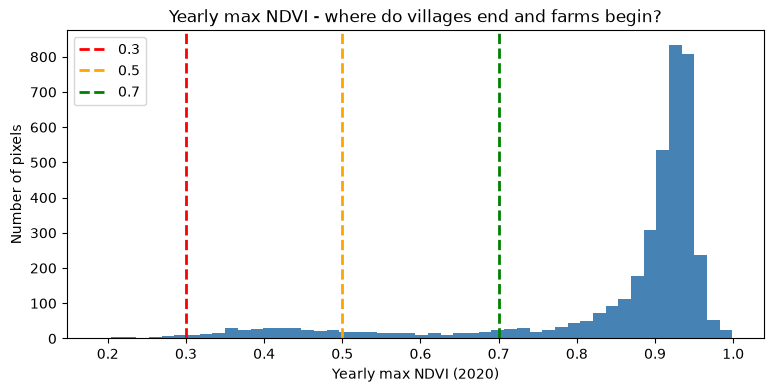

below 0.3:   0.8%
below 0.4:   3.8%
below 0.5:   7.8%
below 0.6:  10.4%
below 0.7:  12.8%
below 0.8:  17.0%


In [ ]:
start = ee.Date.fromYMD(2020, 1, 1)
yearly = (S2.filterBounds(aoi).filterDate(start, start.advance(1, "year"))
            .map(mask_s2).max())

samp = yearly.sample(region=aoi, scale=20, numPixels=4000, seed=1, geometries=False)
feats = retry(lambda: samp.getInfo())["features"]
vals = np.array([f["properties"]["ndvi"] for f in feats])
print("pixels sampled:", len(vals))

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(vals, bins=50, color="steelblue")
for t, c in [(0.3, "red"), (0.5, "orange"), (0.7, "green")]:
    ax.axvline(t, color=c, ls="--", lw=2, label=str(t))
ax.set_xlabel("Yearly max NDVI (2020)")
ax.set_ylabel("Number of pixels")
ax.set_title("Yearly max NDVI - where do villages end and farms begin?")
ax.legend()
plt.show()

for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    print(f"below {t}: {(vals < t).mean() * 100:5.1f}%")

In [16]:
import os, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ee
from concurrent.futures import ThreadPoolExecutor

W, S, E, N = 30.70, 31.05, 30.91, 31.30
LAT_C, LON_C = 31.175, 30.805
START_YEAR, END_YEAR = 2016, 2024
assert 31 <= S < N < 32 and 30 <= W < E < 31, "lat/lon swapped"

ee.Initialize(project="ee-fieldshift")
aoi = ee.Geometry.Rectangle([W, S, E, N])
S2 = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")

def mask_s2(img):
    scl = img.select("SCL")
    clear = scl.eq(4).Or(scl.eq(5)).Or(scl.eq(6)).Or(scl.eq(7))
    return img.normalizedDifference(["B8", "B4"]).rename("ndvi").updateMask(clear)

def monthly_ndvi(year, month):
    start = ee.Date.fromYMD(year, month, 1)
    return (S2.filterBounds(aoi).filterDate(start, start.advance(1, "month"))
              .map(mask_s2).max())

def farm_mask(year):
    start = ee.Date.fromYMD(year, 1, 1)
    yearly = (S2.filterBounds(aoi).filterDate(start, start.advance(1, "year"))
                .map(mask_s2).max())
    return yearly.gt(0.5)

GRID = pd.read_csv("../data/processed/grid_1km.csv")
cells = ee.FeatureCollection([
    ee.Feature(ee.Geometry.Rectangle([r.x_min_m, r.y_min_m, r.x_max_m, r.y_max_m],
                                     proj="EPSG:32636", geodesic=False),
               {"cell_id": int(r.cell_id)})
    for r in GRID.itertuples()])

COLS = ["cell_id", "year", "month", "ndvi_mean", "bare_pct", "low_cover_pct",
        "farm_pct", "valid_pct"]

def cell_stats(year, month, scale=10):
    m = monthly_ndvi(year, month)
    farm = farm_mask(year)
    stack = (m.updateMask(farm).rename("ndvi_mean")
             .addBands(m.lt(0.2).updateMask(farm).rename("bare_pct"))
             .addBands(m.lt(0.35).updateMask(farm).rename("low_cover_pct"))
             .addBands(farm.unmask(0).rename("farm_pct"))
             .addBands(m.mask().rename("valid_pct")))
    fc = stack.reduceRegions(collection=cells, reducer=ee.Reducer.mean(), scale=scale)
    df = pd.DataFrame([f["properties"] for f in fc.getInfo()["features"]])
    df["year"], df["month"] = year, month
    return df[COLS]

print("Setup OK | cells:", len(GRID))

Setup OK | cells: 560


In [17]:
OUT = "../data/raw/s2_cells"
os.makedirs(OUT, exist_ok=True)

jobs = [(y, m) for y in range(START_YEAR, END_YEAR + 1) for m in range(1, 13)
        if not os.path.exists(f"{OUT}/{y}_{m:02d}.csv")]
print("months to do:", len(jobs))

def run_one(job):
    y, m = job
    for attempt in range(3):
        try:
            cell_stats(y, m).to_csv(f"{OUT}/{y}_{m:02d}.csv", index=False)
            return f"{y}-{m:02d} ok"
        except Exception as e:
            if attempt == 2:
                return f"{y}-{m:02d} FAILED {type(e).__name__}"
            time.sleep(15)

t0 = time.time()
with ThreadPoolExecutor(max_workers=6) as ex:
    for i, res in enumerate(ex.map(run_one, jobs), 1):
        print(f"[{i}/{len(jobs)}] {res}  ({time.time() - t0:.0f}s)")

print("\nsaved:", len(os.listdir(OUT)), "of 108 | total:", round((time.time() - t0) / 60, 1), "min")

months to do: 108
[1/108] 2016-01 ok  (22s)
[2/108] 2016-02 ok  (79s)
[3/108] 2016-03 ok  (79s)
[4/108] 2016-04 ok  (79s)
[5/108] 2016-05 ok  (79s)
[6/108] 2016-06 ok  (79s)
[7/108] 2016-07 ok  (79s)
[8/108] 2016-08 ok  (79s)
[9/108] 2016-09 ok  (79s)
[10/108] 2016-10 ok  (82s)
[11/108] 2016-11 ok  (82s)
[12/108] 2016-12 ok  (82s)
[13/108] 2017-01 ok  (136s)
[14/108] 2017-02 ok  (136s)
[15/108] 2017-03 ok  (136s)
[16/108] 2017-04 ok  (208s)
[17/108] 2017-05 ok  (208s)
[18/108] 2017-06 ok  (208s)
[19/108] 2017-07 ok  (208s)
[20/108] 2017-08 ok  (208s)
[21/108] 2017-09 ok  (208s)
[22/108] 2017-10 ok  (208s)
[23/108] 2017-11 ok  (208s)
[24/108] 2017-12 ok  (208s)
[25/108] 2018-01 ok  (330s)
[26/108] 2018-02 ok  (330s)
[27/108] 2018-03 ok  (330s)
[28/108] 2018-04 ok  (330s)
[29/108] 2018-05 ok  (330s)
[30/108] 2018-06 ok  (330s)
[31/108] 2018-07 ok  (330s)
[32/108] 2018-08 ok  (330s)
[33/108] 2018-09 ok  (330s)
[34/108] 2018-10 ok  (330s)
[35/108] 2018-11 ok  (331s)
[36/108] 2018-12 ok  (3

In [13]:
test = cell_stats(2020, 1)
print(test[["ndvi_mean", "bare_pct", "farm_pct", "valid_pct"]].describe().round(3))

       ndvi_mean  bare_pct  farm_pct  valid_pct
count    560.000   560.000   560.000      560.0
mean       0.858     0.001     0.925        1.0
std        0.032     0.007     0.105        0.0
min        0.568     0.000     0.132        1.0
25%        0.848     0.000     0.905        1.0
50%        0.863     0.000     0.965        1.0
75%        0.877     0.000     0.989        1.0
max        0.916     0.148     1.000        1.0


In [14]:
frames = []
for mth in range(1, 13):
    t0 = time.time()
    frames.append(cell_stats(2020, mth))
    print(f"month {mth:2d} done in {time.time() - t0:.0f}s")

y2020 = pd.concat(frames, ignore_index=True)
print("\nrows:", len(y2020))
print(y2020.groupby("month")[["ndvi_mean", "bare_pct"]].mean().round(3))

month  1 done in 2s
month  2 done in 201s
month  3 done in 101s
month  4 done in 8s
month  5 done in 172s
month  6 done in 104s
month  7 done in 16s
month  8 done in 15s
month  9 done in 84s
month 10 done in 15s
month 11 done in 17s
month 12 done in 9s

rows: 6720
       ndvi_mean  bare_pct
month                     
1          0.858     0.001
2          0.848     0.001
3          0.828     0.001
4          0.668     0.007
5          0.461     0.068
6          0.663     0.023
7          0.778     0.015
8          0.751     0.016
9          0.605     0.026
10         0.562     0.045
11         0.709     0.010
12         0.827     0.000


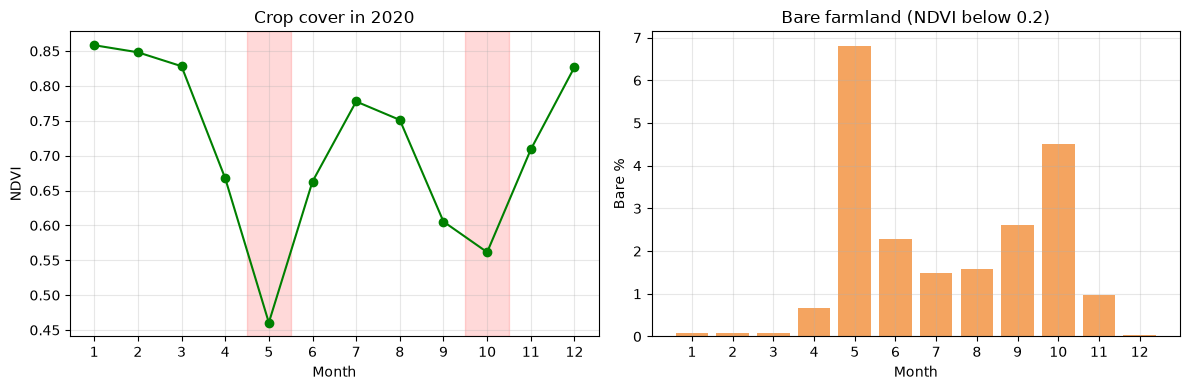

May 2020 - farmland pixels
  below 0.2:   7.4%
  below 0.3:  31.1%
  below 0.35:  40.8%
  below 0.4:  49.3%
  below 0.5:  62.3%


In [15]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
g = y2020.groupby("month")[["ndvi_mean", "bare_pct"]].mean()

a1.plot(g.index, g.ndvi_mean, "o-", color="green")
a1.set_xlabel("Month"); a1.set_ylabel("NDVI"); a1.set_title("Crop cover in 2020")
a1.axvspan(4.5, 5.5, color="red", alpha=0.15)
a1.axvspan(9.5, 10.5, color="red", alpha=0.15)
a1.set_xticks(range(1, 13)); a1.grid(alpha=0.3)

a2.bar(g.index, g.bare_pct * 100, color="sandybrown")
a2.set_xlabel("Month"); a2.set_ylabel("Bare %"); a2.set_title("Bare farmland (NDVI below 0.2)")
a2.set_xticks(range(1, 13)); a2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Test a less strict threshold on the gap month
m5 = monthly_ndvi(2020, 5).updateMask(farm_mask(2020))
samp = m5.sample(region=aoi, scale=20, numPixels=4000, seed=1, geometries=False)
v5 = np.array([f["properties"]["ndvi"] for f in retry(lambda: samp.getInfo())["features"]])
print("May 2020 - farmland pixels")
for t in [0.2, 0.3, 0.35, 0.4, 0.5]:
    print(f"  below {t}: {(v5 < t).mean() * 100:5.1f}%")

In [18]:
files = sorted(os.listdir(OUT))
s2 = pd.concat([pd.read_csv(f"{OUT}/{f}") for f in files], ignore_index=True)
s2 = s2.sort_values(["cell_id", "year", "month"]).reset_index(drop=True)

s2.to_csv("../data/processed/sentinel2_monthly.csv", index=False)

print("rows:", len(s2), "(must be 60480)")
print("months:", s2.groupby(['year','month']).ngroups, "(must be 108)")
print("cells:", s2.cell_id.nunique(), "(must be 560)")
print("\nmissing %:")
print((s2.isna().mean() * 100).round(2))

rows: 60480 (must be 60480)
months: 108 (must be 108)
cells: 560 (must be 560)

missing %:
cell_id          0.00
year             0.00
month            0.00
ndvi_mean        0.77
bare_pct         0.77
low_cover_pct    0.77
farm_pct         0.00
valid_pct        0.00
dtype: float64


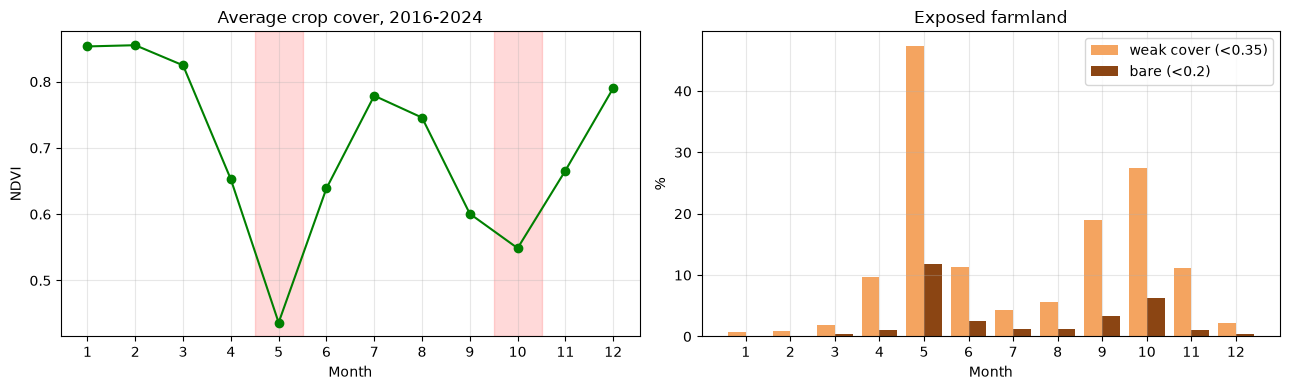

       ndvi_mean  bare_pct  low_cover_pct
month                                    
1          0.853     0.002          0.007
2          0.855     0.001          0.008
3          0.825     0.003          0.019
4          0.653     0.010          0.097
5          0.436     0.118          0.473
6          0.639     0.025          0.113
7          0.779     0.012          0.043
8          0.746     0.013          0.056
9          0.601     0.033          0.190
10         0.549     0.063          0.275
11         0.666     0.010          0.112
12         0.790     0.003          0.023


In [19]:
g = s2.groupby("month")[["ndvi_mean", "bare_pct", "low_cover_pct"]].mean()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.plot(g.index, g.ndvi_mean, "o-", color="green")
a1.axvspan(4.5, 5.5, color="red", alpha=0.15)
a1.axvspan(9.5, 10.5, color="red", alpha=0.15)
a1.set_title("Average crop cover, 2016-2024"); a1.set_xlabel("Month"); a1.set_ylabel("NDVI")
a1.set_xticks(range(1, 13)); a1.grid(alpha=0.3)

a2.bar(g.index - 0.2, g.low_cover_pct * 100, width=0.4, label="weak cover (<0.35)", color="sandybrown")
a2.bar(g.index + 0.2, g.bare_pct * 100, width=0.4, label="bare (<0.2)", color="saddlebrown")
a2.set_title("Exposed farmland"); a2.set_xlabel("Month"); a2.set_ylabel("%")
a2.set_xticks(range(1, 13)); a2.legend(); a2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(g.round(3))

## Conclusion - Sentinel-2

**Output:** `data/processed/sentinel2_monthly.csv` - 60,480 rows (560 cells x 108 months), 2016-01 to 2024-12.

**Main finding:** farmland cover drops twice every year.
- **May**: NDVI 0.44, 47% weak cover, 12% bare. Wheat is harvested and summer crops are not grown yet.
- **October**: NDVI 0.55, 28% weak cover, 6% bare. Summer crops are harvested and winter crops are not grown yet.
- Winter (December to March) is the densest season: NDVI 0.79 to 0.86, almost no bare soil.

**What we checked and fixed:**
1. The offset problem (baseline 04.00, January 2022) is handled by the HARMONIZED collection. We checked January of every year from 2016 to 2024 and found no jump in 2022.
2. The farm mask first used NDVI above 0.3 on the yearly max. This gave 99% farmland, which is wrong. We looked at the histogram of yearly max NDVI and changed it to 0.5, which gives 92.5% farmland. Two independent checks both say villages and roads are about 8% of the area.
3. "Bare" at NDVI below 0.2 was too strict, because harvested fields with crop residue sit around 0.25 to 0.35. So we report two columns: bare (below 0.2) and weak cover (below 0.35).

**Known limits:**
- 2016 and 2017 have lower NDVI than later years. This is because only one Sentinel-2 satellite was flying until March 2017, so there were fewer clear images. It is not a real change in the crops. Do not use it as a trend.
- The histogram of yearly max NDVI has no sharp valley between 0.5 and 0.8. These are mixed pixels (village edges, roads next to fields). This is normal in the dense Nile Delta.
- 0.77% of rows have no NDVI. These are cells with almost no farmland, such as cells inside a town.

**Why Earth Engine:** downloading the images to a laptop took 12 to 32 minutes per month (22 to 57 hours for 9 years). Earth Engine does the computation on Google's servers and returns only the small table. The same 9 years took 30 minutes. The data is the same Sentinel-2 (ESA) from the challenge resources.

# Part C - Landsat (40-year change)

Sentinel-2 shows the farm now (2016-2024).
Landsat goes back to 1985, so it shows if the area is changing over 40 years.

Output: `landsat_yearly.csv` - one row per cell per year.

In [20]:
# ===== LANDSAT SETUP =====
L_COLS = ["cell_id", "year", "ndvi_max_mean", "n_images", "farm_pct"]

def prep_landsat(img):
    """Scale, mask clouds, compute NDVI. Band names differ by satellite."""
    qa = img.select("QA_PIXEL")
    # bits 0 fill, 1 dilated cloud, 3 cloud, 4 cloud shadow
    bad = (qa.bitwiseAnd(1 << 0).neq(0)
           .Or(qa.bitwiseAnd(1 << 1).neq(0))
           .Or(qa.bitwiseAnd(1 << 3).neq(0))
           .Or(qa.bitwiseAnd(1 << 4).neq(0)))
    sr = img.select(["RED", "NIR"]).multiply(0.0000275).add(-0.2)
    ndvi = sr.normalizedDifference(["NIR", "RED"]).rename("ndvi")
    return ndvi.updateMask(bad.Not())

def landsat_year(year):
    """All Landsat images of one year, with matching band names."""
    start, end = f"{year}-01-01", f"{year}-12-31"
    old = ["SR_B3", "SR_B4", "QA_PIXEL"]      # Landsat 5 and 7
    new = ["SR_B4", "SR_B5", "QA_PIXEL"]      # Landsat 8 and 9
    names = ["RED", "NIR", "QA_PIXEL"]
    cols = []
    for cid, bands in [("LANDSAT/LT05/C02/T1_L2", old),
                       ("LANDSAT/LE07/C02/T1_L2", old),
                       ("LANDSAT/LC08/C02/T1_L2", new),
                       ("LANDSAT/LC09/C02/T1_L2", new)]:
        c = (ee.ImageCollection(cid).filterBounds(aoi).filterDate(start, end)
               .select(bands, names))
        cols.append(c)
    return cols[0].merge(cols[1]).merge(cols[2]).merge(cols[3])

def landsat_cell_stats(year, scale=30):
    col = landsat_year(year)
    n = col.size()
    yearly = col.map(prep_landsat).max()
    farm = yearly.gt(0.5)
    stack = (yearly.updateMask(farm).rename("ndvi_max_mean")
             .addBands(farm.unmask(0).rename("farm_pct")))
    fc = stack.reduceRegions(collection=cells, reducer=ee.Reducer.mean(), scale=scale)
    df = pd.DataFrame([f["properties"] for f in fc.getInfo()["features"]])
    df["year"] = year
    df["n_images"] = n.getInfo()
    return df[L_COLS]

print("Landsat setup OK")

Landsat setup OK


In [21]:
t0 = time.time()
t = landsat_cell_stats(2020)
print("time:", round(time.time() - t0, 1), "s | rows:", len(t), "| images:", t.n_images.iloc[0])
print(t[["ndvi_max_mean", "farm_pct"]].describe().round(3))

time: 41.5 s | rows: 560 | images: 87
       ndvi_max_mean  farm_pct
count        560.000   560.000
mean           0.852     0.932
std            0.024     0.103
min            0.714     0.095
25%            0.838     0.914
50%            0.855     0.972
75%            0.869     0.993
max            0.902     1.000


In [22]:
LOUT = "../data/raw/landsat_cells"
os.makedirs(LOUT, exist_ok=True)

ljobs = [y for y in range(1985, 2025) if not os.path.exists(f"{LOUT}/{y}.csv")]
print("years to do:", len(ljobs))

def run_year(y):
    for attempt in range(3):
        try:
            landsat_cell_stats(y).to_csv(f"{LOUT}/{y}.csv", index=False)
            return f"{y} ok"
        except Exception as e:
            if attempt == 2:
                return f"{y} FAILED {type(e).__name__}"
            time.sleep(15)

t0 = time.time()
with ThreadPoolExecutor(max_workers=6) as ex:
    for i, res in enumerate(ex.map(run_year, ljobs), 1):
        print(f"[{i}/{len(ljobs)}] {res}  ({time.time() - t0:.0f}s)")

print("\nsaved:", len(os.listdir(LOUT)), "of 40 | total:", round((time.time() - t0) / 60, 1), "min")

years to do: 40
[1/40] 1985 ok  (11s)
[2/40] 1986 ok  (19s)
[3/40] 1987 ok  (23s)
[4/40] 1988 ok  (23s)
[5/40] 1989 ok  (31s)
[6/40] 1990 ok  (31s)
[7/40] 1991 ok  (31s)
[8/40] 1992 ok  (40s)
[9/40] 1993 ok  (41s)
[10/40] 1994 ok  (51s)
[11/40] 1995 ok  (51s)
[12/40] 1996 ok  (51s)
[13/40] 1997 ok  (51s)
[14/40] 1998 ok  (51s)
[15/40] 1999 ok  (59s)
[16/40] 2000 ok  (60s)
[17/40] 2001 ok  (60s)
[18/40] 2002 ok  (60s)
[19/40] 2003 ok  (62s)
[20/40] 2004 ok  (80s)
[21/40] 2005 ok  (87s)
[22/40] 2006 ok  (91s)
[23/40] 2007 ok  (91s)
[24/40] 2008 ok  (91s)
[25/40] 2009 ok  (91s)
[26/40] 2010 ok  (91s)
[27/40] 2011 ok  (91s)
[28/40] 2012 ok  (91s)
[29/40] 2013 ok  (106s)
[30/40] 2014 ok  (127s)
[31/40] 2015 ok  (127s)
[32/40] 2016 ok  (127s)
[33/40] 2017 ok  (127s)
[34/40] 2018 ok  (127s)
[35/40] 2019 ok  (159s)
[36/40] 2020 ok  (159s)
[37/40] 2021 ok  (188s)
[38/40] 2022 ok  (196s)
[39/40] 2023 ok  (196s)
[40/40] 2024 ok  (196s)

saved: 40 of 40 | total: 3.3 min


rows: 22400 (must be 22400)
years: 40 | cells: 560
missing %: {'cell_id': 0.0, 'year': 0.0, 'ndvi_max_mean': 0.0, 'n_images': 0.0, 'farm_pct': 0.0}


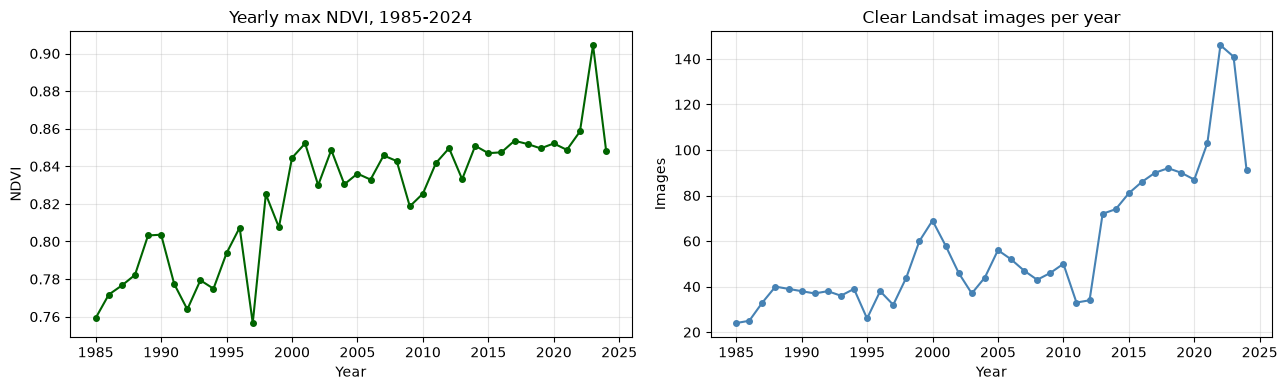


NDVI change: +0.0250 per 10 years
farmland: 0.922 (1985-89) -> 0.931 (2020-24)


In [23]:
lfiles = sorted(os.listdir(LOUT))
ls = pd.concat([pd.read_csv(f"{LOUT}/{f}") for f in lfiles], ignore_index=True)
ls = ls.sort_values(["cell_id", "year"]).reset_index(drop=True)
ls.to_csv("../data/processed/landsat_yearly.csv", index=False)

print("rows:", len(ls), "(must be 22400)")
print("years:", ls.year.nunique(), "| cells:", ls.cell_id.nunique())
print("missing %:", (ls.isna().mean() * 100).round(2).to_dict())

# The 40-year picture
g = ls.groupby("year").agg(ndvi=("ndvi_max_mean", "mean"),
                           farm=("farm_pct", "mean"),
                           imgs=("n_images", "first"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.plot(g.index, g.ndvi, "o-", color="darkgreen", ms=4)
a1.set_title("Yearly max NDVI, 1985-2024"); a1.set_xlabel("Year"); a1.set_ylabel("NDVI")
a1.grid(alpha=0.3)
a2.plot(g.index, g.imgs, "o-", color="steelblue", ms=4)
a2.set_title("Clear Landsat images per year"); a2.set_xlabel("Year"); a2.set_ylabel("Images")
a2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Is there a real trend?
from numpy.polynomial import polynomial as Pl
yrs = g.index.values.astype(float)
slope = np.polyfit(yrs, g.ndvi.values, 1)[0]
print(f"\nNDVI change: {slope * 10:+.4f} per 10 years")
print(f"farmland: {g.farm.iloc[:5].mean():.3f} (1985-89) -> {g.farm.iloc[-5:].mean():.3f} (2020-24)")

correlation between image count and NDVI: 0.723

years with few images  (<45): 19 years, mean NDVI 0.799
years with many images (>=45): 21 years, mean NDVI 0.845


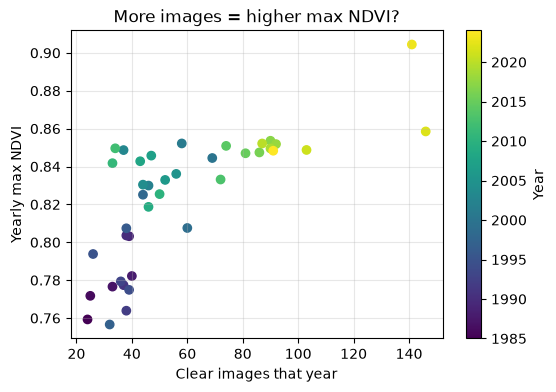

In [24]:
r = np.corrcoef(g.imgs.values, g.ndvi.values)[0, 1]
print(f"correlation between image count and NDVI: {r:.3f}")

old = g[g.imgs < 45]
new = g[g.imgs >= 45]
print(f"\nyears with few images  (<45): {len(old)} years, mean NDVI {old.ndvi.mean():.3f}")
print(f"years with many images (>=45): {len(new)} years, mean NDVI {new.ndvi.mean():.3f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(g.imgs, g.ndvi, c=g.index, cmap="viridis")
ax.set_xlabel("Clear images that year"); ax.set_ylabel("Yearly max NDVI")
ax.set_title("More images = higher max NDVI?"); ax.grid(alpha=0.3)
plt.colorbar(ax.collections[0], label="Year"); plt.show()

In [30]:
def landsat_winter_stats(year, scale=30):
    full = landsat_year(year)
    farm = full.map(prep_landsat).max().gt(0.5)
    wcol = full.filter(ee.Filter.calendarRange(2, 3, "month"))
    nw = wcol.size()
    wmean = wcol.map(prep_landsat).mean().updateMask(farm)
    fc = wmean.reduceRegions(collection=cells, reducer=ee.Reducer.mean(), scale=scale)
    df = pd.DataFrame([f["properties"] for f in fc.getInfo()["features"]])
    df = df.rename(columns={"mean": "ndvi_winter_mean"})
    df["year"] = year
    df["n_winter"] = nw.getInfo()
    return df[["cell_id", "year", "ndvi_winter_mean", "n_winter"]]

In [29]:
full = landsat_year(2020)
farm = full.map(prep_landsat).max().gt(0.5)
wcol = full.filter(ee.Filter.calendarRange(2, 3, "month"))
print("winter images:", wcol.size().getInfo())

wmean = wcol.map(prep_landsat).mean().rename("ndvi_winter_mean").updateMask(farm)
print("band names:", wmean.bandNames().getInfo())

fc = wmean.reduceRegions(collection=cells, reducer=ee.Reducer.mean(), scale=30)
df = pd.DataFrame([f["properties"] for f in fc.getInfo()["features"]])
print("columns:", df.columns.tolist())
print(df.head(3))

winter images: 15
band names: ['ndvi_winter_mean']
columns: ['cell_id', 'mean']
   cell_id      mean
0        1  0.690986
1        2  0.744641
2        3  0.715963


In [31]:
WOUT = "../data/raw/landsat_winter"
os.makedirs(WOUT, exist_ok=True)
wjobs = [y for y in range(1985, 2025) if not os.path.exists(f"{WOUT}/{y}.csv")]

def run_w(y):
    for a in range(3):
        try:
            landsat_winter_stats(y).to_csv(f"{WOUT}/{y}.csv", index=False)
            return f"{y} ok"
        except Exception as e:
            if a == 2:
                return f"{y} FAILED: {type(e).__name__}: {e}"
            time.sleep(10)

t0 = time.time()
with ThreadPoolExecutor(max_workers=6) as ex:
    for i, r_ in enumerate(ex.map(run_w, wjobs), 1):
        print(f"[{i}/{len(wjobs)}] {r_}  ({time.time()-t0:.0f}s)")
print("done in", round((time.time()-t0)/60, 1), "min")

[1/40] 1985 ok  (9s)
[2/40] 1986 ok  (17s)
[3/40] 1987 ok  (17s)
[4/40] 1988 ok  (17s)
[5/40] 1989 ok  (23s)
[6/40] 1990 ok  (23s)
[7/40] 1991 ok  (29s)
[8/40] 1992 ok  (30s)
[9/40] 1993 ok  (35s)
[10/40] 1994 ok  (41s)
[11/40] 1995 ok  (42s)
[12/40] 1996 ok  (42s)
[13/40] 1997 ok  (42s)
[14/40] 1998 ok  (66s)
[15/40] 1999 ok  (66s)
[16/40] 2000 ok  (73s)
[17/40] 2001 ok  (73s)
[18/40] 2002 ok  (73s)
[19/40] 2003 ok  (73s)
[20/40] 2004 ok  (73s)
[21/40] 2005 ok  (78s)
[22/40] 2006 ok  (78s)
[23/40] 2007 ok  (78s)
[24/40] 2008 ok  (110s)
[25/40] 2009 ok  (110s)
[26/40] 2010 ok  (110s)
[27/40] 2011 ok  (110s)
[28/40] 2012 ok  (110s)
[29/40] 2013 ok  (118s)
[30/40] 2014 ok  (118s)
[31/40] 2015 ok  (118s)
[32/40] 2016 ok  (131s)
[33/40] 2017 ok  (164s)
[34/40] 2018 ok  (164s)
[35/40] 2019 ok  (164s)
[36/40] 2020 ok  (164s)
[37/40] 2021 ok  (217s)
[38/40] 2022 ok  (217s)
[39/40] 2023 ok  (217s)
[40/40] 2024 ok  (217s)
done in 3.6 min


rows: 22400 | columns: ['cell_id', 'year', 'ndvi_max_mean', 'n_images', 'farm_pct', 'ndvi_winter_mean', 'n_winter']

method                  corr with images   trend per 10y
yearly MAX (old)                   0.723         +0.0250
winter MEAN (new)                  0.169         +0.0185


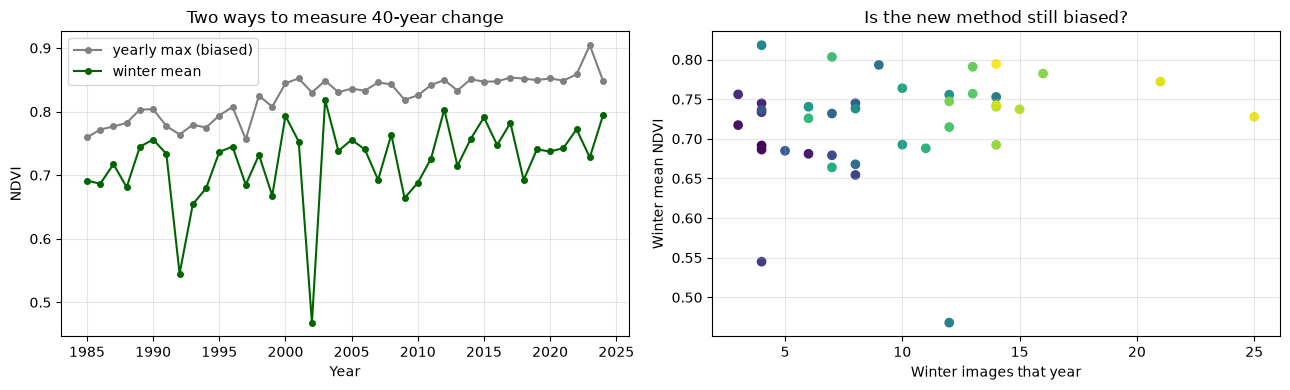

In [32]:
wfiles = sorted(os.listdir(WOUT))
w = pd.concat([pd.read_csv(f"{WOUT}/{f}") for f in wfiles], ignore_index=True)

ls2 = ls.merge(w, on=["cell_id", "year"], how="left")
ls2.to_csv("../data/processed/landsat_yearly.csv", index=False)
print("rows:", len(ls2), "| columns:", ls2.columns.tolist())

gw = ls2.groupby("year").agg(ndvi_max=("ndvi_max_mean", "mean"),
                             ndvi_winter=("ndvi_winter_mean", "mean"),
                             imgs=("n_images", "first"),
                             n_w=("n_winter", "first"))

r_max = np.corrcoef(gw.imgs, gw.ndvi_max)[0, 1]
r_win = np.corrcoef(gw.n_w, gw.ndvi_winter)[0, 1]
s_max = np.polyfit(gw.index.astype(float), gw.ndvi_max, 1)[0] * 10
s_win = np.polyfit(gw.index.astype(float), gw.ndvi_winter, 1)[0] * 10

print(f"\n{'method':22s} {'corr with images':>17s} {'trend per 10y':>15s}")
print(f"{'yearly MAX (old)':22s} {r_max:17.3f} {s_max:+15.4f}")
print(f"{'winter MEAN (new)':22s} {r_win:17.3f} {s_win:+15.4f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.plot(gw.index, gw.ndvi_max, "o-", color="gray", ms=4, label="yearly max (biased)")
a1.plot(gw.index, gw.ndvi_winter, "o-", color="darkgreen", ms=4, label="winter mean")
a1.set_xlabel("Year"); a1.set_ylabel("NDVI"); a1.legend(); a1.grid(alpha=0.3)
a1.set_title("Two ways to measure 40-year change")
a2.scatter(gw.n_w, gw.ndvi_winter, c=gw.index, cmap="viridis")
a2.set_xlabel("Winter images that year"); a2.set_ylabel("Winter mean NDVI")
a2.set_title("Is the new method still biased?"); a2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Conclusion - Landsat

**Output:** `data/processed/landsat_yearly.csv` - 22,400 rows (560 cells x 40 years), 1985 to 2024.

**Columns:**
- `ndvi_max_mean`: highest NDVI of the year. Kept for reference only - see the problem below.
- `ndvi_winter_mean`: mean NDVI in February and March. **Use this one for the trend.**
- `n_images`, `n_winter`: how many clear images were used.

**A problem we found and fixed.**
Our first method used the highest NDVI of each year. It showed the area getting greener by +0.025 per 10 years.
But the number of clear Landsat images per year grew from 24 in 1985 to over 140 in 2022.
With more images, you have a better chance of catching the peak day, so the yearly maximum goes up by itself.
The correlation between image count and yearly max NDVI was **0.723** - too high to trust.

So we changed the method: the **mean** NDVI of February and March (the peak winter season, which we found from Sentinel-2).
A mean does not go up when you add more images.
The correlation dropped to **0.169**, and the trend became **+0.0185 per 10 years**.

**What this means:** the area really is getting greener, but about a quarter of the first number was an artifact of the satellites, not a change in the land.

**Cross-check with Sentinel-2:** Landsat says 93.2% of the area is farmland, Sentinel-2 says 92.5%.
Two different satellites at different resolutions (30 m and 10 m) agree, which supports our farm mask.

**Known limits:**
- The winter mean is noisier than the yearly max, because some years have only 3 or 4 clear winter images. 1992 and 2002 are clear outliers and should not be read as real events.
- Band numbers differ between satellites (Landsat 5 and 7 use SR_B3 and SR_B4; Landsat 8 and 9 use SR_B4 and SR_B5). We handled this by renaming bands to RED and NIR before merging.
- Landsat 7 images after May 2003 have missing stripes. Taking a mean or max over many images reduces this, but it is not fully removed.